# Fertilizer Prediction Kaggle Playground
This notebook covers EDA, baselines, XGBoost, LightGBM, depth tuning, three
seeds, error analysis, profiling, and the final artifact. It is designed to run
on Kaggle and locally.

1,000 estimators, depths `[4, 6, 8]`, seeds `[42, 2025, 7]`.

In [ ]:
# %pip install -q --upgrade "sqlalchemy==2.0.41"
# %pip install -q mlflow==2.22.0 xgboost==2.1.4 lightgbm==4.5.0

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# 1. Setup

In [2]:
# %pip install -q --upgrade "sqlalchemy==2.0.41"
# %pip install -q mlflow==2.22.0 xgboost==2.1.4 lightgbm==4.5.0


from __future__ import annotations

import cProfile
import hashlib
import json
import os
import platform
import random
import subprocess
import sys
import time
import warnings
import zipfile
from datetime import datetime, timezone
from importlib.metadata import version as pkg_version
from pathlib import Path
from pstats import SortKey, Stats

import joblib
import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, log_loss
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

In [3]:
SEEDS = [42, 2025, 7]
PRIMARY_SEED = 42
N_CLASSES_EXPECTED = 7
N_ESTIMATORS = 1000
EARLY_STOPPING_ROUNDS = 50
LEARNING_RATE = 0.08
SUBSAMPLE = 0.8
COLSAMPLE = 0.8
REG_LAMBDA = 1.0
DEPTH_GRID = [4, 6, 8]
TARGET = "Fertilizer Name"
ID_COL = "id"
RAW_NUM_COLS = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous",
]
CAT_COLS = ["Soil Type", "Crop Type"]

FAST_DEV = os.environ.get("FAST_DEV", "0") == "1"
MAX_ROWS = None
if FAST_DEV:
    N_ESTIMATORS = 40
    DEPTH_GRID = [4, 6]
    SEEDS = [42, 7]
    MAX_ROWS = 20_000
    print("WARNING: FAST_DEV=1 — reduced settings. Do not use these results as final evidence.")
else:
    print("Full run: n_estimators=1000, depths=[4, 6, 8], seeds=[42, 2025, 7].")


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


set_seed(PRIMARY_SEED)

print("python:", sys.version.split()[0])
print("platform:", platform.platform())
print("CPU count:", os.cpu_count())
try:
    import psutil

    print("RAM GB:", round(psutil.virtual_memory().total / 1e9, 1))
except Exception as exc:
    print("RAM: unavailable", exc)

GPU_INFO = "none"
HAS_GPU = False
try:
    gpu = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        capture_output=True,
        text=True,
        timeout=20,
    )
    if gpu.returncode == 0 and gpu.stdout.strip():
        GPU_INFO = gpu.stdout.strip()
        HAS_GPU = True
except Exception:
    pass
print("GPU:", GPU_INFO)

try:
    mlflow_version = pkg_version("mlflow")
except Exception:
    mlflow_version = "not installed"

try:
    sqlalchemy_version = pkg_version("sqlalchemy")
except Exception:
    sqlalchemy_version = "not installed"

VERSION_PINS = {
    "numpy": ("2.2.6", np.__version__),
    "pandas": ("2.2.3", pd.__version__),
    "scikit-learn": ("1.5.2", sklearn.__version__),
    "scipy": ("1.15.3", scipy.__version__),
    "xgboost": ("2.1.4", xgb.__version__),
    "lightgbm": ("4.5.0", lgb.__version__),
    "mlflow": ("2.22.0", mlflow_version),
    "sqlalchemy": ("2.0.41", sqlalchemy_version),
    "matplotlib": ("3.9.2", matplotlib.__version__),
    "seaborn": ("0.13.2", sns.__version__),
}
for name, (pinned, actual) in VERSION_PINS.items():
    flag = "OK" if pinned == actual else "MISMATCH"
    print(f"{name:14s} pinned={pinned:10s} actual={actual:10s} {flag}")

if any(pinned != actual for pinned, actual in VERSION_PINS.values()):
    print(
        "NOTE: MISMATCH is informational. On Kaggle Python 3.13, compiled "
        "packages use Kaggle's preinstalled builds; record the actual versions."
    )


Full run: n_estimators=1000, depths=[4, 6, 8], seeds=[42, 2025, 7].
python: 3.13.16
platform: Linux-6.18.55+-x86_64-with-glibc2.39
CPU count: 4
RAM GB: 33.7
GPU: Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
numpy          pinned=2.2.6      actual=2.1.3      MISMATCH
pandas         pinned=2.2.3      actual=2.3.3      MISMATCH
scikit-learn   pinned=1.5.2      actual=1.6.1      MISMATCH
scipy          pinned=1.15.3     actual=1.16.3     MISMATCH
xgboost        pinned=2.1.4      actual=2.1.4      OK
lightgbm       pinned=4.5.0      actual=4.5.0      OK
mlflow         pinned=2.22.0     actual=2.22.0     OK
sqlalchemy     pinned=2.0.41     actual=2.0.41     OK
matplotlib     pinned=3.9.2      actual=3.10.0     MISMATCH
seaborn        pinned=0.13.2     actual=0.13.2     OK
NOTE: MISMATCH is informational. On Kaggle Python 3.13, compiled packages use Kaggle's preinstalled builds; record the actual versions.


In [4]:
def resolve_data_dir() -> Path:
    env_dir = os.environ.get("FERTILIZER_DATA_DIR")
    if env_dir:
        candidate = Path(env_dir).expanduser().resolve()
        if (candidate / "train.csv").exists() and (candidate / "test.csv").exists():
            return candidate
        raise FileNotFoundError(
            f"FERTILIZER_DATA_DIR does not contain train.csv/test.csv: {candidate}"
        )

    if Path("/kaggle/input").exists():
        candidates = []
        for train_path in sorted(Path("/kaggle/input").glob("**/train.csv")):
            d = train_path.parent
            if (d / "test.csv").exists() and (d / "sample_submission.csv").exists():
                candidates.append(d)
        for d in candidates:
            if "s5e6" in str(d).lower() or "fertilizer" in str(d).lower():
                return d
        if candidates:
            return candidates[0]

    for d in [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd() / "data",
        Path.cwd().parent / "data",
    ]:
        if (d / "train.csv").exists() and (d / "test.csv").exists():
            return d
    raise FileNotFoundError(
        "Could not locate train.csv/test.csv. Set FERTILIZER_DATA_DIR."
    )


DATA_DIR = resolve_data_dir()
if Path("/kaggle/working").exists():
    DEFAULT_WORK_DIR = Path("/kaggle/working")
else:
    DEFAULT_WORK_DIR = DATA_DIR.parent
WORK_DIR = Path(
    os.environ.get("FERTILIZER_WORK_DIR", DEFAULT_WORK_DIR)
).expanduser().resolve()
LOGS = WORK_DIR / "logs"
MODELS = WORK_DIR / "models"
FIG_DIR = LOGS / "figures"
RUN_MODELS = MODELS / "runs"
for d in (WORK_DIR, LOGS, MODELS, FIG_DIR, RUN_MODELS):
    d.mkdir(parents=True, exist_ok=True)

print("DATA_DIR:", DATA_DIR)
print("WORK_DIR:", WORK_DIR)
print("MLflow is not initialized yet; it starts before the first tracked run.")

DATA_DIR: /kaggle/input/competitions/playground-series-s5e6
WORK_DIR: /kaggle/working
MLflow is not initialized yet; it starts before the first tracked run.


## 1.1 Quick look at the data


In [5]:
t0 = time.perf_counter()
train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")
LOAD_SECONDS = time.perf_counter() - t0

if MAX_ROWS is not None:
    train_raw = train_raw.sample(
        n=min(MAX_ROWS, len(train_raw)), random_state=PRIMARY_SEED
    ).reset_index(drop=True)
    test_raw = test_raw.sample(
        n=min(MAX_ROWS, len(test_raw)), random_state=PRIMARY_SEED
    ).reset_index(drop=True)
    print(f"FAST_DEV sample: train={len(train_raw):,}, test={len(test_raw):,}")

EDA_LINES = []


def record(text=""):
    text = str(text)
    print(text)
    EDA_LINES.append(text)


record(f"load_seconds={LOAD_SECONDS:.4f}")
record(f"train_shape={train_raw.shape}")
record(f"test_shape={test_raw.shape}")
record(f"sample_submission_shape={sample_sub.shape}")

print("\ntrain.head():")
display(train_raw.head())
print("\ntest.head():")
display(test_raw.head())
print("\nsample_submission.head():")
display(sample_sub.head())
print("\nrandom train sample:")
display(train_raw.sample(5, random_state=PRIMARY_SEED))

record("\nDtypes (train):")
record(train_raw.dtypes.to_string())
record("\nNumeric summary (train):")
record(train_raw[RAW_NUM_COLS].describe().T.round(3).to_string())
record("\nUnique value counts (numeric):")
record(train_raw[RAW_NUM_COLS].nunique().to_string())

record(f"\nTarget classes ({train_raw[TARGET].nunique()}):")
record(sorted(train_raw[TARGET].unique().tolist()))
record(f"Soil types ({train_raw['Soil Type'].nunique()}):")
record(sorted(train_raw["Soil Type"].unique().tolist()))
record(f"Crop types ({train_raw['Crop Type'].nunique()}):")
record(sorted(train_raw["Crop Type"].unique().tolist()))

record("\nMissing values before dropna (train):")
record(train_raw.isna().sum().to_string())
record("\nMissing values before dropna (test):")
record(test_raw.isna().sum().to_string())

train_before, test_before = len(train_raw), len(test_raw)
train_raw = train_raw.dropna().reset_index(drop=True)
test_raw = test_raw.dropna().reset_index(drop=True)
record(
    f"\ndropna: train {train_before:,} -> {len(train_raw):,}; "
    f"test {test_before:,} -> {len(test_raw):,}"
)

record(f"\nDuplicate rows (train): {train_raw.duplicated().sum()}")
record(f"Duplicate ids (train): {train_raw[ID_COL].duplicated().sum()}")
record(f"Duplicate ids (test): {test_raw[ID_COL].duplicated().sum()}")
record(
    "Train/test id overlap: "
    f"{len(set(train_raw[ID_COL]) & set(test_raw[ID_COL]))}"
)

load_seconds=1.6134
train_shape=(750000, 10)
test_shape=(250000, 9)
sample_submission_shape=(250000, 2)

train.head():


,id,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,0,37,70,36,Clayey,Sugarcane,36,4,5,28-28
1,1,27,69,65,Sandy,Millets,30,6,18,28-28
2,2,29,63,32,Sandy,Millets,24,12,16,17-17-17
3,3,35,62,54,Sandy,Barley,39,12,4,10-26-26
4,4,35,58,43,Red,Paddy,37,2,16,DAP



test.head():


,id,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous
0,750000,31,70,52,Sandy,Wheat,34,11,24
1,750001,27,62,45,Red,Sugarcane,30,14,15
2,750002,28,72,28,Clayey,Ground Nuts,14,15,4
3,750003,37,53,57,Black,Ground Nuts,18,17,36
4,750004,31,55,32,Red,Pulses,13,19,14



sample_submission.head():


,id,Fertilizer Name
0,750000,14-35-14 10-26-26 Urea
1,750001,14-35-14 10-26-26 Urea
2,750002,14-35-14 10-26-26 Urea
3,750003,14-35-14 10-26-26 Urea
4,750004,14-35-14 10-26-26 Urea



random train sample:


,id,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
404846,404846,30,72,51,Sandy,Oil seeds,42,9,30,17-17-17
580313,580313,36,57,48,Loamy,Cotton,19,11,20,14-35-14
552086,552086,29,67,60,Sandy,Paddy,28,13,30,10-26-26
370876,370876,29,67,53,Loamy,Millets,13,10,38,14-35-14
239330,239330,35,68,34,Clayey,Tobacco,31,17,28,10-26-26



Dtypes (train):
id                  int64
Temparature         int64
Humidity            int64
Moisture            int64
Soil Type          object
Crop Type          object
Nitrogen            int64
Potassium           int64
Phosphorous         int64
Fertilizer Name    object

Numeric summary (train):
                count    mean     std   min   25%   50%   75%   max
Temparature  750000.0  31.504   4.026  25.0  28.0  32.0  35.0  38.0
Humidity     750000.0  61.039   6.648  50.0  55.0  61.0  67.0  72.0
Moisture     750000.0  45.184  11.795  25.0  35.0  45.0  55.0  65.0
Nitrogen     750000.0  23.094  11.216   4.0  13.0  23.0  33.0  42.0
Potassium    750000.0   9.478   5.766   0.0   4.0   9.0  14.0  19.0
Phosphorous  750000.0  21.073  12.347   0.0  10.0  21.0  32.0  42.0

Unique value counts (numeric):
Temparature    14
Humidity       23
Moisture       41
Nitrogen       39
Potassium      20
Phosphorous    43

Target classes (7):
['10-26-26', '14-35-14', '17-17-17', '20-20', '28-28', 'DAP'

## 2. EDA


Target counts:
Fertilizer Name
14-35-14    114436
10-26-26    113887
17-17-17    112453
28-28       111158
20-20       110889
DAP          94860
Urea         92317

Target share:
Fertilizer Name
14-35-14    0.1526
10-26-26    0.1518
17-17-17    0.1499
28-28       0.1482
20-20       0.1479
DAP         0.1265
Urea        0.1231


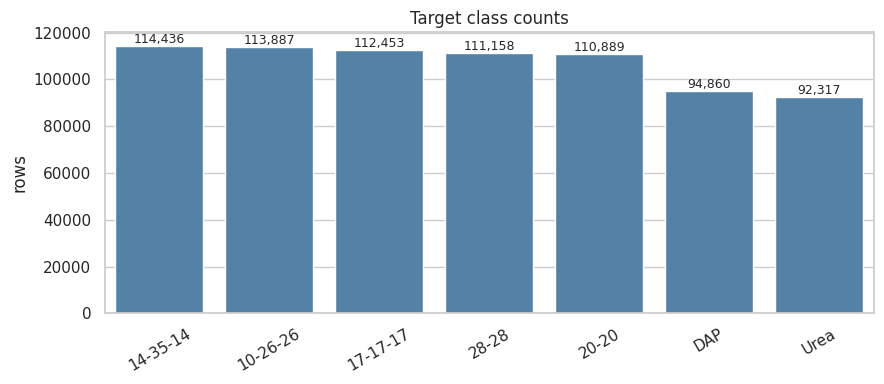

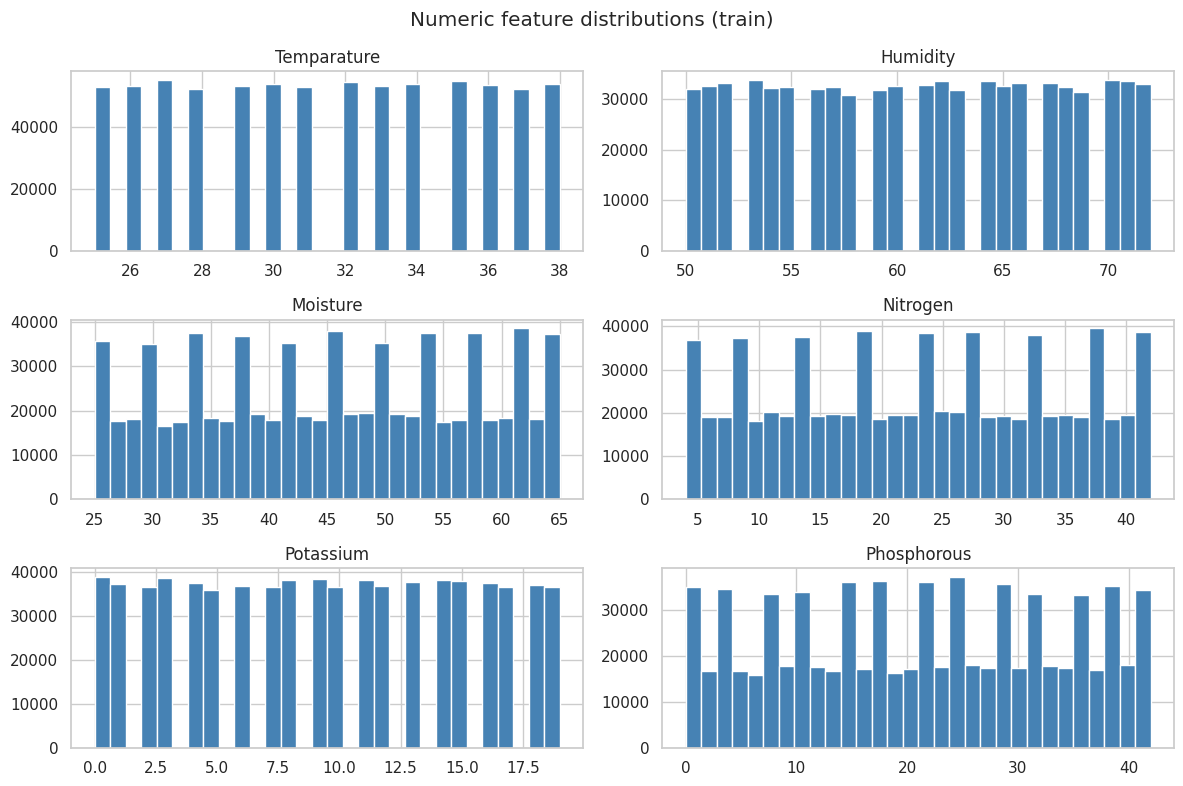

In [6]:
record("\nTarget counts:")
counts = train_raw[TARGET].value_counts()
record(counts.to_string())
record("\nTarget share:")
record((counts / counts.sum()).round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="steelblue")
ax.set_title("Target class counts")
ax.set_xlabel("")
ax.set_ylabel("rows")
ax.tick_params(axis="x", rotation=30)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "target_counts.png", dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)

axes = train_raw[RAW_NUM_COLS].hist(
    figsize=(12, 8), bins=30, color="steelblue", edgecolor="white"
)
fig = axes[0, 0].get_figure()
fig.suptitle("Numeric feature distributions (train)")
fig.tight_layout()
fig.savefig(FIG_DIR / "numeric_hist.png", dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)


Categorical counts (train):

Soil Type:
Soil Type
Sandy     156710
Black     150956
Clayey    148382
Red       148102
Loamy     145850

Crop Type:
Crop Type
Paddy          85754
Pulses         78180
Cotton         69171
Tobacco        68000
Wheat          66628
Millets        65291
Barley         65045
Sugarcane      64269
Oil seeds      64184
Maize          62569
Ground Nuts    60909

Class-conditional numeric means:
                 Temparature  Humidity  Moisture  Nitrogen  Potassium  Phosphorous
Fertilizer Name                                                                   
10-26-26              31.471    60.937    45.076    23.203      9.555       20.981
14-35-14              31.543    60.963    45.100    23.083      9.485       21.410
17-17-17              31.464    60.999    44.740    23.205      9.524       21.054
20-20                 31.514    61.104    45.317    23.008      9.590       21.111
28-28                 31.519    61.013    45.500    23.013      9.478       21.

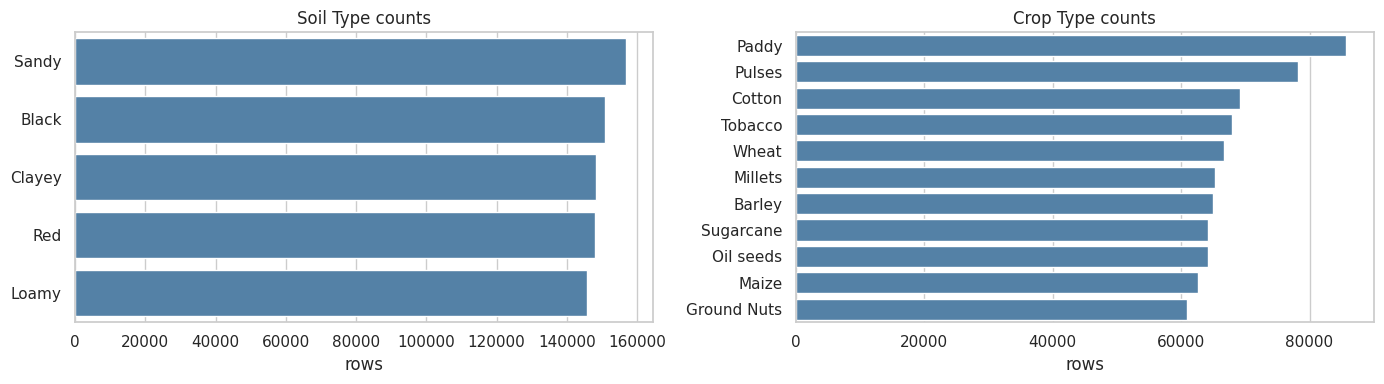


Wrote /kaggle/working/logs/eda_summary.txt


In [7]:
record("\nCategorical counts (train):")
for col in CAT_COLS:
    record(f"\n{col}:")
    record(train_raw[col].value_counts().to_string())

means = train_raw.groupby(TARGET)[RAW_NUM_COLS].mean().round(3)
record("\nClass-conditional numeric means:")
record(means.to_string())
record("\nClass-mean range (max - min):")
record((means.max() - means.min()).round(3).to_string())

f_vals, p_vals = f_classif(train_raw[RAW_NUM_COLS], train_raw[TARGET])
anova = pd.DataFrame(
    {"feature": RAW_NUM_COLS, "F": f_vals, "p": p_vals}
).set_index("feature")
record("\nOne-way ANOVA F-test (feature vs target):")
record(anova.round(4).to_string())
record(
    "Interpretation: p-values are tiny only because n is large. "
    "The class-mean range is the meaningful effect size, and it is small."
)

train_test = pd.DataFrame(
    {
        "train_mean": train_raw[RAW_NUM_COLS].mean(),
        "test_mean": test_raw[RAW_NUM_COLS].mean(),
        "train_std": train_raw[RAW_NUM_COLS].std(),
        "test_std": test_raw[RAW_NUM_COLS].std(),
    }
)
train_test["mean_delta"] = train_test["test_mean"] - train_test["train_mean"]
record("\nTrain vs test numeric comparison:")
record(train_test.round(3).to_string())

record("\nTrain vs test categorical shares:")
for col in CAT_COLS:
    tr = train_raw[col].value_counts(normalize=True).rename("train")
    te = test_raw[col].value_counts(normalize=True).rename("test")
    record(f"\n{col}:")
    record(pd.concat([tr, te], axis=1).fillna(0).round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, CAT_COLS):
    order = train_raw[col].value_counts().index
    sns.countplot(data=train_raw, y=col, order=order, ax=ax, color="steelblue")
    ax.set_title(f"{col} counts")
    ax.set_xlabel("rows")
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "categorical_counts.png", dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)

(LOGS / "eda_summary.txt").write_text("\n".join(EDA_LINES) + "\n")
print(f"\nWrote {LOGS / 'eda_summary.txt'}")

## 3. Cleaning

Changes are deliberately small:

- Rename the competition's misspelled `Temparature` to `Temperature`.
- Drop `id`  it is a row key, not a feature.

The split is an 80/20 stratified holdout with seed 42

In [8]:
t0 = time.perf_counter()
train = (
    train_raw.rename(columns={"Temparature": "Temperature"})
    .drop(columns=[ID_COL])
    .copy()
)
test = (
    test_raw.rename(columns={"Temparature": "Temperature"})
    .drop(columns=[ID_COL])
    .copy()
)
NUM_COLS = [
    "Temperature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous",
]
FEATURE_COLS = NUM_COLS + CAT_COLS

class_names = np.array(sorted(train[TARGET].unique()))
assert len(class_names) == N_CLASSES_EXPECTED, (
    f"expected {N_CLASSES_EXPECTED} classes, got {len(class_names)}"
)
assert set(test.columns) == set(FEATURE_COLS), "test columns do not match features"
assert train[FEATURE_COLS].isna().sum().sum() == 0, "train has missing features"
assert test[FEATURE_COLS].isna().sum().sum() == 0, "test has missing features"

label_encoder = LabelEncoder().fit(train[TARGET])
y_all = label_encoder.transform(train[TARGET])
assert np.array_equal(label_encoder.classes_, class_names)

X_all = train[FEATURE_COLS].copy()
X_test_raw = test[FEATURE_COLS].copy()

X_tr, X_va, y_tr, y_va = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    random_state=PRIMARY_SEED,
    stratify=y_all,
)
print(f"train={len(X_tr):,} validation={len(X_va):,} test={len(X_test_raw):,}")
print("classes:", list(class_names))
print("no imputation needed: 0 missing values in train/test feature columns")
PREP_SECONDS = time.perf_counter() - t0

train=600,000 validation=150,000 test=250,000
classes: [np.str_('10-26-26'), np.str_('14-35-14'), np.str_('17-17-17'), np.str_('20-20'), np.str_('28-28'), np.str_('DAP'), np.str_('Urea')]
no imputation needed: 0 missing values in train/test feature columns


In [9]:
def make_preprocessor(numeric_cols, categorical_cols, scale_numeric=False):
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer(
        transformers=[
            ("num", numeric_step, numeric_cols),
            (
                "cat",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                    dtype=np.float32,
                ),
                categorical_cols,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


t0 = time.perf_counter()
preprocessor = make_preprocessor(NUM_COLS, CAT_COLS, scale_numeric=False)
X_tr_enc = preprocessor.fit_transform(X_tr)
X_va_enc = preprocessor.transform(X_va)
X_test_enc = preprocessor.transform(X_test_raw)
ENCODE_SECONDS = time.perf_counter() - t0
TOTAL_PREP_SECONDS = PREP_SECONDS + ENCODE_SECONDS
ENCODED_FEATURES = list(preprocessor.get_feature_names_out())

print(
    "encoded shape: "
    f"train={X_tr_enc.shape}, validation={X_va_enc.shape}, test={X_test_enc.shape}"
)
print(f"encoded features ({len(ENCODED_FEATURES)}):", ENCODED_FEATURES)
print(f"encoding_seconds={ENCODE_SECONDS:.4f}")

encoded shape: train=(600000, 22), validation=(150000, 22), test=(250000, 22)
encoded features (22): ['Temperature', 'Humidity', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous', 'Soil Type_Black', 'Soil Type_Clayey', 'Soil Type_Loamy', 'Soil Type_Red', 'Soil Type_Sandy', 'Crop Type_Barley', 'Crop Type_Cotton', 'Crop Type_Ground Nuts', 'Crop Type_Maize', 'Crop Type_Millets', 'Crop Type_Oil seeds', 'Crop Type_Paddy', 'Crop Type_Pulses', 'Crop Type_Sugarcane', 'Crop Type_Tobacco', 'Crop Type_Wheat']
encoding_seconds=0.6117


## 4. Metrics

Used Map@3 

In [10]:
def map3(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1, 1)
    y_pred = np.asarray(y_pred)[:, :3]
    hit = y_pred == y_true
    weights = 1.0 / np.arange(1, 4)
    return float((hit * weights).sum(axis=1).mean())


def top3_from_proba(proba):
    return np.argsort(-np.asarray(proba), axis=1)[:, :3]


def map3_from_proba(y_true, proba):
    return map3(y_true, top3_from_proba(proba))


def multiclass_logloss(y_true, proba):
    return float(
        log_loss(y_true, proba, labels=np.arange(N_CLASSES_EXPECTED))
    )


assert map3([0], [[0, 1, 2]]) == 1.0
assert map3([1], [[0, 1, 2]]) == 0.5
assert map3([2], [[0, 1, 2]]) == 1.0 / 3.0
assert map3([3], [[0, 1, 2]]) == 0.0
print("MAP@3 sanity checks passed")

MAP@3 sanity checks passed


## 5. Baselines

Three floors before the first real model:

- **Random top-3** rank three classes at random.
- **Majority top-3** always predict the three most frequent training classes.
- **Logistic regression** one-hot categoricals, scaled numerics, multinomial
  logistic regression. This is the linear reference point.

In [11]:
rng = np.random.default_rng(PRIMARY_SEED)
random_scores = rng.random((len(y_va), N_CLASSES_EXPECTED))
random_top3 = top3_from_proba(random_scores)
random_map3 = map3(y_va, random_top3)

class_counts = np.bincount(y_tr, minlength=N_CLASSES_EXPECTED)
majority_top3 = np.argsort(-class_counts)[:3]
majority_pred = np.tile(majority_top3, (len(y_va), 1))
majority_map3 = map3(y_va, majority_pred)

t0 = time.perf_counter()
logreg = Pipeline(
    [
        ("prep", make_preprocessor(NUM_COLS, CAT_COLS, scale_numeric=True)),
        (
            "clf",
            LogisticRegression(
                max_iter=2000,
                random_state=PRIMARY_SEED,
                n_jobs=-1,
            ),
        ),
    ]
)
logreg.fit(X_tr, y_tr)
logreg_seconds = time.perf_counter() - t0
logreg_proba = logreg.predict_proba(X_va)
logreg_map3 = map3_from_proba(y_va, logreg_proba)
logreg_logloss = multiclass_logloss(y_va, logreg_proba)

BASELINES = {
    "random_top3": {
        "val_map3": float(random_map3),
    },
    "majority_top3": {
        "val_map3": float(majority_map3),
        "classes": [str(class_names[i]) for i in majority_top3],
    },
    "logistic_regression": {
        "val_map3": float(logreg_map3),
        "val_logloss": float(logreg_logloss),
        "train_seconds": float(logreg_seconds),
    },
}

baseline_df = pd.DataFrame(
    [
        {"model": "random_top3", "val_map3": random_map3, "val_logloss": np.nan},
        {"model": "majority_top3", "val_map3": majority_map3, "val_logloss": np.nan},
        {
            "model": "logistic_regression",
            "val_map3": logreg_map3,
            "val_logloss": logreg_logloss,
        },
    ]
).sort_values("val_map3", ascending=False)

print(baseline_df.to_string(index=False))
print("majority top-3:", [class_names[i] for i in majority_top3])
print(f"logistic regression fit seconds={logreg_seconds:.2f}")

              model  val_map3  val_logloss
logistic_regression  0.287219     1.939336
      majority_top3  0.278483          NaN
        random_top3  0.260510          NaN
majority top-3: [np.str_('14-35-14'), np.str_('10-26-26'), np.str_('17-17-17')]
logistic regression fit seconds=4.18


## 6. XGBoost

7-class cross-entropy XGBoost, early stopping on validation logloss, and a GPU attempt with CPU fallback.

The helper below is written for reuse in the depth-tuning and seed sections. It
does not initialize MLflow; that happens immediately before the first call.

In [12]:
XGB_RESULTS = {}
PROFILE = {}


def xgb_device_order():
    return ["cuda", "cpu"] if HAS_GPU else ["cpu"]


def make_xgb(depth, seed, device):
    return xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=N_CLASSES_EXPECTED,
        n_estimators=N_ESTIMATORS,
        learning_rate=LEARNING_RATE,
        max_depth=depth,
        subsample=SUBSAMPLE,
        colsample_bytree=COLSAMPLE,
        reg_lambda=REG_LAMBDA,
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        eval_metric="mlogloss",
        tree_method="hist",
        device=device,
        random_state=seed,
        n_jobs=-1,
    )


def plot_learning_curves(train_loss, val_loss, title, path, show=True):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, len(train_loss) + 1), train_loss, label="train", linewidth=1.5)
    ax.plot(range(1, len(val_loss) + 1), val_loss, label="validation", linewidth=1.5)
    ax.set_xlabel("iteration")
    ax.set_ylabel("mlogloss")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=130, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)
    return path


def fit_xgb(
    depth,
    seed,
    X_train,
    y_train,
    X_val,
    y_val,
    run_name,
    feature_names,
    log_model=True,
    profile=False,
    show_curve=True,
):
    last_error = None
    model = None
    device_used = None
    train_seconds = None

    for device in xgb_device_order():
        candidate = make_xgb(depth, seed, device)
        try:
            t0 = time.perf_counter()
            if profile:
                profiler = cProfile.Profile()
                profiler.enable()
                candidate.fit(
                    X_train,
                    y_train,
                    eval_set=[(X_train, y_train), (X_val, y_val)],
                    verbose=False,
                )
                profiler.disable()
                PROFILE["xgb_fit"] = profiler
            else:
                candidate.fit(
                    X_train,
                    y_train,
                    eval_set=[(X_train, y_train), (X_val, y_val)],
                    verbose=False,
                )
            train_seconds = time.perf_counter() - t0
            model = candidate
            device_used = device
            break
        except Exception as exc:
            last_error = exc
            print(f"XGBoost device={device} failed: {exc}")
            if device == "cpu":
                raise
            print("Falling back to CPU.")

    if model is None:
        raise RuntimeError(f"XGBoost training failed: {last_error}")

    evals = model.evals_result()
    train_loss = [float(v) for v in evals["validation_0"]["mlogloss"]]
    val_loss = [float(v) for v in evals["validation_1"]["mlogloss"]]
    best_iter_raw = getattr(model, "best_iteration", None)
    best_iter = (
        int(best_iter_raw)
        if best_iter_raw is not None
        else int(model.n_estimators) - 1
    )
    proba = model.predict_proba(X_val, iteration_range=(0, best_iter + 1))
    val_logloss = multiclass_logloss(y_val, proba)
    val_map3 = map3_from_proba(y_val, proba)

    fig_path = FIG_DIR / f"{run_name}_learning_curve.png"
    plot_learning_curves(
        train_loss,
        val_loss,
        f"{run_name} learning curves",
        fig_path,
        show=show_curve,
    )

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params(
            {
                "model_family": "xgboost",
                "objective": "multi:softprob",
                "depth": depth,
                "seed": seed,
                "n_estimators": N_ESTIMATORS,
                "learning_rate": LEARNING_RATE,
                "subsample": SUBSAMPLE,
                "colsample_bytree": COLSAMPLE,
                "reg_lambda": REG_LAMBDA,
                "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
                "device": device_used,
                "n_features": int(X_train.shape[1]),
                "train_rows": int(X_train.shape[0]),
                "val_rows": int(X_val.shape[0]),
                "fast_dev": FAST_DEV,
            }
        )
        mlflow.set_tag("note", "rebuild of lost June 2025 work")
        mlflow.set_tag("model_family", "xgboost")
        mlflow.set_tag("seed", str(seed))
        mlflow.set_tag("device", device_used)
        for i, (tr, va) in enumerate(zip(train_loss, val_loss)):
            mlflow.log_metrics({"train_logloss": tr, "val_logloss": va}, step=i)
        mlflow.log_metric("best_iteration", best_iter)
        mlflow.log_metric("val_logloss_best", val_logloss)
        mlflow.log_metric("val_map3", val_map3)
        mlflow.log_metric("train_seconds", train_seconds)
        mlflow.log_artifact(str(fig_path), artifact_path="plots")
        if log_model:
            model_path = RUN_MODELS / f"{run_name}.joblib"
            joblib.dump(
                {
                    "model": model,
                    "feature_names": list(feature_names),
                    "classes": class_names.tolist(),
                    "depth": depth,
                    "seed": seed,
                    "best_iteration": best_iter,
                    "val_logloss": val_logloss,
                    "val_map3": val_map3,
                },
                model_path,
                compress=3,
            )
            mlflow.log_artifact(str(model_path), artifact_path="model")
        RUN_IDS[run_name] = run.info.run_id
        run_id = run.info.run_id

    (LOGS / "mlflow_runs.json").write_text(
        json.dumps(RUN_IDS, indent=2) + "\n"
    )

    result = {
        "model": model,
        "depth": depth,
        "seed": seed,
        "best_iter": best_iter,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_logloss": val_logloss,
        "val_map3": val_map3,
        "train_seconds": train_seconds,
        "device": device_used,
        "run_name": run_name,
        "run_id": run_id,
        "feature_names": list(feature_names),
        "val_proba": proba,
    }
    print(
        f"{run_name}: device={device_used} best_iter={best_iter} "
        f"val_logloss={val_logloss:.6f} val_map3={val_map3:.6f} "
        f"train_seconds={train_seconds:.2f}"
    )
    return result

### 6.1 MLflow setup 

For Tracking

In [13]:
import mlflow
from mlflow.tracking import MlflowClient

MLFLOW_DB = WORK_DIR / "mlflow.db"
MLRUNS_DIR = WORK_DIR / "mlruns"
EXPERIMENT_NAME = "fertilizer-s5e6"

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

# MLflow 2.22's SQLite store imports FallbackAsyncAdaptedQueuePool, which is
# missing from older SQLAlchemy builds (common on Kaggle). Fail with a clear
# fix instead of a deep ImportError.
try:
    from sqlalchemy.pool import FallbackAsyncAdaptedQueuePool  # noqa: F401
except ImportError as exc:
    raise RuntimeError(
        "MLflow 2.22's SQLite backend needs SQLAlchemy with "
        "FallbackAsyncAdaptedQueuePool. Run:\n"
        "  %pip install -q --upgrade \"sqlalchemy==2.0.41\"\n"
        "then restart the kernel and rerun this cell."
    ) from exc

import sqlalchemy

print("SQLAlchemy:", sqlalchemy.__version__)
client = MlflowClient()
experiment = client.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    client.create_experiment(
        EXPERIMENT_NAME,
        artifact_location=MLRUNS_DIR.as_uri(),
    )
mlflow.set_experiment(EXPERIMENT_NAME)

RUN_IDS = {}
print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

SQLAlchemy: 2.0.41


2026/11/22 15:45:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/22 15:45:43 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
INFO  [alembic.runtime.migration] Running upgrade 7ac759974ad8 -> 89d4b8295536, create latest metrics table
INFO  [89d4b8295536_create_latest_metrics_table_py] Migration complete!
INFO  

MLflow tracking URI: sqlite:////kaggle/working/mlflow.db
MLflow experiment: fertilizer-s5e6


### 6.2 First XGBoost run

Depth 6, seed 42

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:158: UserWarning: [15:46:25] WARNING: /workspace/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  warnings.warn(smsg, UserWarning)


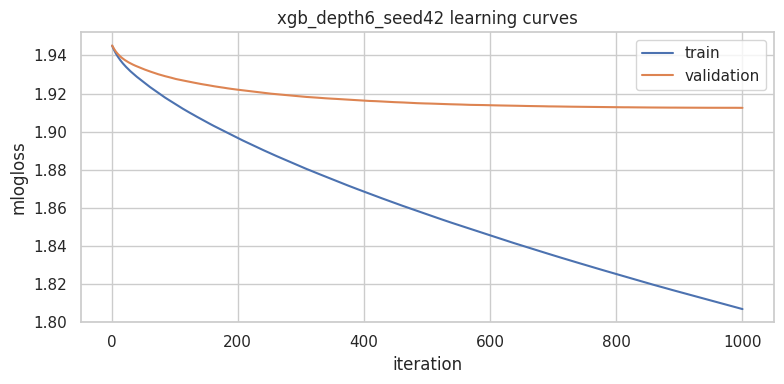

xgb_depth6_seed42: device=cuda best_iter=998 val_logloss=1.912498 val_map3=0.340220 train_seconds=40.70


In [14]:
initial_xgb = fit_xgb(
    depth=6,
    seed=PRIMARY_SEED,
    X_train=X_tr_enc,
    y_train=y_tr,
    X_val=X_va_enc,
    y_val=y_va,
    run_name="xgb_depth6_seed42",
    feature_names=ENCODED_FEATURES,
    log_model=True,
    profile=False,
    show_curve=True,
)
XGB_RESULTS[(6, PRIMARY_SEED)] = initial_xgb

## 7. LightGBM run 

Same split, same early stopping criteria, same depth (6), seed 42. LightGBM and comparison with XGboost

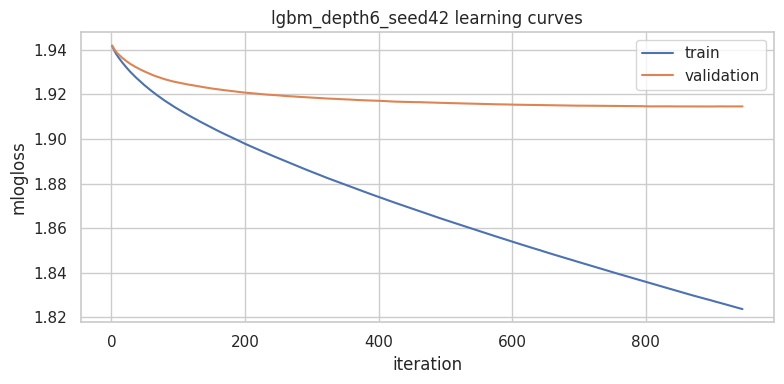

lgbm_depth6_seed42: device=cpu best_iter=895 val_logloss=1.914583 val_map3=0.337351 train_seconds=161.89


In [15]:
LGBM_RESULTS = {}


def fit_lgbm(
    depth,
    seed,
    X_train,
    y_train,
    X_val,
    y_val,
    run_name,
    feature_names,
    log_model=True,
    show_curve=True,
):
    model = lgb.LGBMClassifier(
        objective="multiclass",
        num_class=N_CLASSES_EXPECTED,
        n_estimators=N_ESTIMATORS,
        learning_rate=LEARNING_RATE,
        max_depth=depth,
        num_leaves=31,
        subsample=SUBSAMPLE,
        subsample_freq=1,
        colsample_bytree=COLSAMPLE,
        reg_lambda=REG_LAMBDA,
        random_state=seed,
        n_jobs=-1,
        verbose=-1,
    )

    t0 = time.perf_counter()
    model.fit(
        X_train,
        y_train,
        eval_set=[(X_train, y_train), (X_val, y_val)],
        eval_metric="multi_logloss",
        callbacks=[
            lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False),
            lgb.log_evaluation(0),
        ],
    )
    train_seconds = time.perf_counter() - t0

    evals = model.evals_result_
    train_loss = [float(v) for v in evals["training"]["multi_logloss"]]
    val_loss = [float(v) for v in evals["valid_1"]["multi_logloss"]]
    best_iter = max(1, int(model.best_iteration_))
    proba = model.predict_proba(X_val, num_iteration=best_iter)
    val_logloss = multiclass_logloss(y_val, proba)
    val_map3 = map3_from_proba(y_val, proba)

    fig_path = FIG_DIR / f"{run_name}_learning_curve.png"
    plot_learning_curves(
        train_loss,
        val_loss,
        f"{run_name} learning curves",
        fig_path,
        show=show_curve,
    )

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params(
            {
                "model_family": "lightgbm",
                "objective": "multiclass",
                "depth": depth,
                "num_leaves": 31,
                "seed": seed,
                "n_estimators": N_ESTIMATORS,
                "learning_rate": LEARNING_RATE,
                "subsample": SUBSAMPLE,
                "subsample_freq": 1,
                "colsample_bytree": COLSAMPLE,
                "reg_lambda": REG_LAMBDA,
                "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
                "device": "cpu",
                "n_features": int(X_train.shape[1]),
                "train_rows": int(X_train.shape[0]),
                "val_rows": int(X_val.shape[0]),
                "fast_dev": FAST_DEV,
            }
        )
        mlflow.set_tag("note", "rebuild of lost June 2025 work")
        mlflow.set_tag("model_family", "lightgbm")
        mlflow.set_tag("seed", str(seed))
        mlflow.set_tag("device", "cpu")
        for i, (tr, va) in enumerate(zip(train_loss, val_loss)):
            mlflow.log_metrics({"train_logloss": tr, "val_logloss": va}, step=i)
        mlflow.log_metric("best_iteration", best_iter)
        mlflow.log_metric("val_logloss_best", val_logloss)
        mlflow.log_metric("val_map3", val_map3)
        mlflow.log_metric("train_seconds", train_seconds)
        mlflow.log_artifact(str(fig_path), artifact_path="plots")
        if log_model:
            model_path = RUN_MODELS / f"{run_name}.joblib"
            joblib.dump(
                {
                    "model": model,
                    "feature_names": list(feature_names),
                    "classes": class_names.tolist(),
                    "depth": depth,
                    "seed": seed,
                    "best_iteration": best_iter,
                    "val_logloss": val_logloss,
                    "val_map3": val_map3,
                },
                model_path,
                compress=3,
            )
            mlflow.log_artifact(str(model_path), artifact_path="model")
        RUN_IDS[run_name] = run.info.run_id
        run_id = run.info.run_id

    (LOGS / "mlflow_runs.json").write_text(
        json.dumps(RUN_IDS, indent=2) + "\n"
    )

    result = {
        "model": model,
        "depth": depth,
        "seed": seed,
        "best_iter": best_iter,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_logloss": val_logloss,
        "val_map3": val_map3,
        "train_seconds": train_seconds,
        "device": "cpu",
        "run_name": run_name,
        "run_id": run_id,
        "feature_names": list(feature_names),
        "val_proba": proba,
    }
    print(
        f"{run_name}: device=cpu best_iter={best_iter} "
        f"val_logloss={val_logloss:.6f} val_map3={val_map3:.6f} "
        f"train_seconds={train_seconds:.2f}"
    )
    return result


lgbm_result = fit_lgbm(
    depth=6,
    seed=PRIMARY_SEED,
    X_train=X_tr_enc,
    y_train=y_tr,
    X_val=X_va_enc,
    y_val=y_va,
    run_name="lgbm_depth6_seed42",
    feature_names=ENCODED_FEATURES,
    log_model=True,
    show_curve=True,
)
LGBM_RESULTS[(6, PRIMARY_SEED)] = lgbm_result

In [16]:
comparison = pd.DataFrame(
    [
        {
            "model": "logistic_regression",
            "val_logloss": logreg_logloss,
            "val_map3": logreg_map3,
        },
        {
            "model": "xgboost_depth6_seed42",
            "val_logloss": initial_xgb["val_logloss"],
            "val_map3": initial_xgb["val_map3"],
        },
        {
            "model": "lightgbm_depth6_seed42",
            "val_logloss": lgbm_result["val_logloss"],
            "val_map3": lgbm_result["val_map3"],
        },
    ]
).sort_values("val_map3", ascending=False)

print(comparison.to_string(index=False))
print(
    "LightGBM - XGBoost MAP@3: "
    f"{lgbm_result['val_map3'] - initial_xgb['val_map3']:+.6f}"
)
print(
    "LightGBM - XGBoost logloss: "
    f"{lgbm_result['val_logloss'] - initial_xgb['val_logloss']:+.6f}"
)

comparison_payload = {
    "baselines": BASELINES,
    "xgboost_depth6_seed42": {
        "val_logloss": initial_xgb["val_logloss"],
        "val_map3": initial_xgb["val_map3"],
        "best_iter": initial_xgb["best_iter"],
        "run_id": initial_xgb["run_id"],
    },
    "lightgbm_depth6_seed42": {
        "val_logloss": lgbm_result["val_logloss"],
        "val_map3": lgbm_result["val_map3"],
        "best_iter": lgbm_result["best_iter"],
        "run_id": lgbm_result["run_id"],
    },
}
(LOGS / "model_comparison.json").write_text(
    json.dumps(comparison_payload, indent=2, default=str) + "\n"
)
print(f"Wrote {LOGS / 'model_comparison.json'}")

                 model  val_logloss  val_map3
 xgboost_depth6_seed42     1.912498  0.340220
lightgbm_depth6_seed42     1.914583  0.337351
   logistic_regression     1.939336  0.287219
LightGBM - XGBoost MAP@3: -0.002869
LightGBM - XGBoost logloss: +0.002086
Wrote /kaggle/working/logs/model_comparison.json
